In [1]:
import pandas as pd
import re

# Load the merged fantasy dataset
fantasy_df = pd.read_csv('data/fantasy_dataset.csv')

# Remove leading shirt numbers from player names, e.g. '8Bruno Fernandes' -> 'Bruno Fernandes'
fantasy_df['Player'] = fantasy_df['Player'].astype(str).str.replace(r'^[0-9]+', '', regex=True)


#fantasy_df.to_csv('data/player_stats.csv', index=False)

# Quick checks
print(fantasy_df.shape)
print(fantasy_df[['Player']].head())
print(fantasy_df.columns.tolist())


(1691, 63)
             Player
0  Bruno Fernandes 
1    Erling Haaland
2     Luka Vuskovic
3  Virgil van Dijk 
4           Gabriel
['Player', 'Pos', 'Club', 'Avg', 'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP', 'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT', 'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW', 'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC', 'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG', 'sheet_name', 'league', 'season', 'Price']


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd

# Requested features for predicting Avg
feature_cols = [
    'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP',
    'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT',
    'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW',
    'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC',
    'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG'
]

# Keep only rows with target and features available
model_df = fantasy_df.copy()
for col in feature_cols + ['Avg']:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')

model_df = model_df.dropna(subset=['Avg'] + feature_cols).copy()

X = model_df[feature_cols]
y = model_df['Avg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# LightGBM model pipeline
try:
    import lightgbm as lgb

    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', lgb.LGBMRegressor(
            objective='regression',
            random_state=42,
            n_estimators=1000,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.9,
            colsample_bytree=0.9,
            verbose=-1
        ))
    ])

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = mean_squared_error(y_test, preds) ** 0.5
    r2 = r2_score(y_test, preds)

    print(f'LightGBM RMSE: {rmse:.3f}')
    print(f'LightGBM R^2: {r2:.3f}')

    model_df['predicted_Avg'] = model.predict(X)
    top_players = model_df[['Player', 'Pos', 'Club', 'Avg', 'predicted_Avg']].sort_values(
        'predicted_Avg', ascending=False
    ).head(20)

    print('\nTop predicted players by Avg:')
    print(top_players.to_string(index=False))

except ImportError:
    print('lightgbm is not installed. Install it with: pip install lightgbm')

LightGBM RMSE: 0.947
LightGBM R^2: 0.896

Top predicted players by Avg:
          Player Pos Club  Avg  predicted_Avg
    Lamine Yamal  FW  BAR 26.9      25.645474
     Harry Kane   FW  FCB 25.3      24.650830
   Michael Olise  FW  FCB 22.0      22.023336
 Ousmane Dembélé  FW  PSG 21.4      21.186679
    Lamine Yamal  FW  BAR 20.4      20.854703
   Omar Marmoush  FW  TOT 20.9      20.799069
        Raphinha  FW  BAR 20.0      20.133989
  Kylian Mbappé   FW  RMA 19.8      19.943815
Bruno Fernandes  MID  MUN 19.9      19.895768
   Michael Olise  FW  FCB 19.8      19.819612
  Kylian Mbappé   FW  RMA 19.5      19.319409
    Bryan Mbeumo  FW  MUN 18.1      19.152065
    Xavi Simons  MID  TOT 18.6      18.582706
 Vinicius Junior  FW  RMA 15.1      18.443566
           Isco  MID  BET 18.4      18.396014
   Jamal Musiala MID  FCB 18.3      18.298830
    Yan Diomande  FW  RBL 18.1      18.101734
    Yan Diomande  FW  RMA 18.1      18.101734
   Andrey Santos MID  MUN 17.7      17.698362
       L

Top 20 most important features:
feature  importance
   Apps        1302
      G        1236
    DUW        1185
    PLS        1155
     Sh        1030
   PAS%         933
     GC         916
   SOFF         903
    DUE         858
    PFT         847
    Clr         812
    REC         812
    LBW         807
     KP         794
    AER         764
     TB         759
     LB         737
     BC         723
    FDR         713
    SoT         712


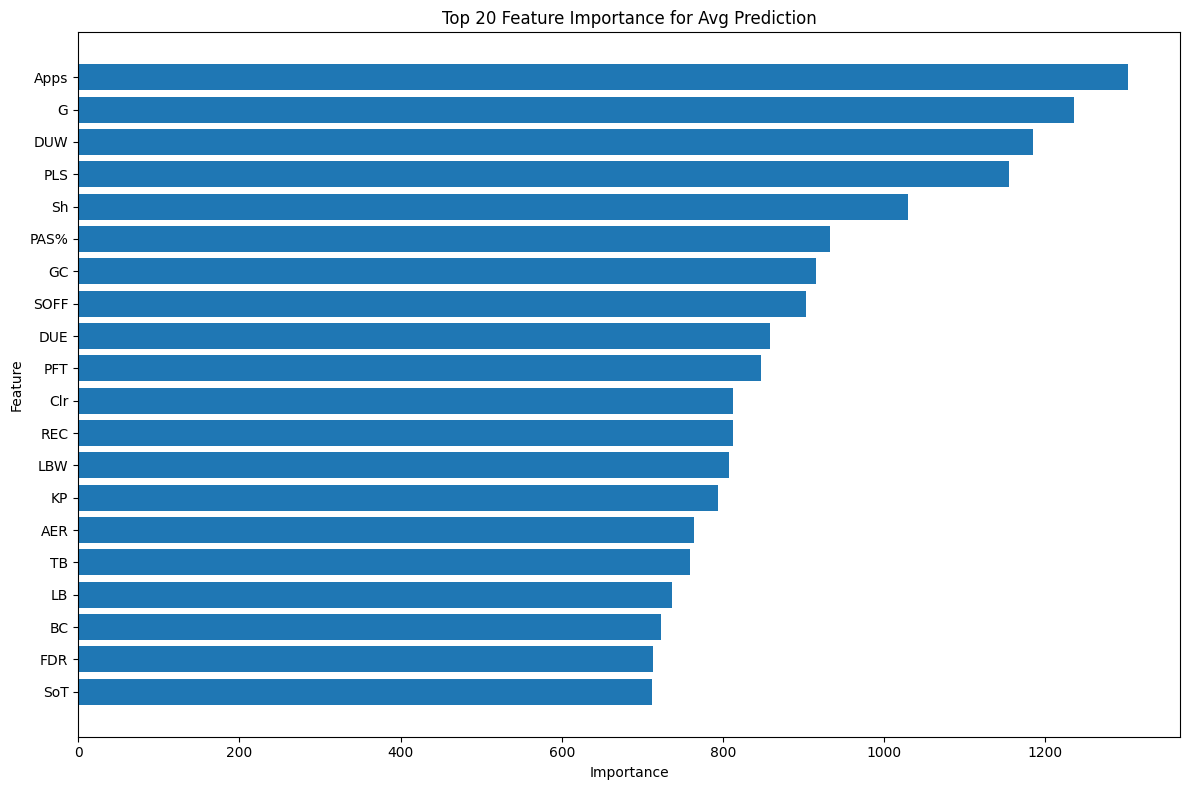

In [3]:
# Feature importance from the trained LightGBM model
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.named_steps['model'].feature_importances_
}).sort_values('importance', ascending=False)

print('Top 20 most important features:')
print(feature_importance.head(20).to_string(index=False))

# Optional: plot feature importance
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12, 8))
    plt.barh(feature_importance.head(20)['feature'][::-1], feature_importance.head(20)['importance'][::-1])
    plt.title('Top 20 Feature Importance for Avg Prediction')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()
except ImportError:
    print('matplotlib not installed; install with: pip install matplotlib')


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd

# Clean and prepare the training dataset
model_df = fantasy_df.copy()
for col in [
    'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP',
    'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT',
    'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW',
    'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC',
    'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG', 'Avg'
]:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')

# Keep only rows with target and features available
model_df = model_df.dropna(subset=['Avg'] + [
    'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP',
    'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT',
    'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW',
    'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC',
    'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG'
]).copy()

# Split by position
position_datasets = {}
for pos in ['FW', 'MID', 'DEF', 'GK']:
    position_datasets[pos] = model_df[model_df['Pos'] == pos].copy()

# Train one LightGBM model per position
models = {}
metrics = {}

for pos, df_pos in position_datasets.items():
    feature_cols = [
        'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP',
        'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT',
        'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW',
        'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC',
        'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG'
    ]

    X = df_pos[feature_cols]
    y = df_pos['Avg']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    import lightgbm as lgb

    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', lgb.LGBMRegressor(
            objective='regression',
            random_state=42,
            n_estimators=1000,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.9,
            colsample_bytree=0.9,
            verbose=-1
        ))
    ])

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = mean_squared_error(y_test, preds) ** 0.5
    r2 = r2_score(y_test, preds)

    models[pos] = model
    metrics[pos] = {'RMSE': rmse, 'R2': r2}

    print(f'\n{pos} model:')
    print(f'RMSE: {rmse:.3f}')
    print(f'R^2: {r2:.3f}')

    df_pos = df_pos.copy()
    df_pos['predicted_Avg'] = model.predict(df_pos[feature_cols])
    ranking = df_pos[['Player', 'Club', 'Avg', 'predicted_Avg']].sort_values('predicted_Avg', ascending=False).head(10)
    print(ranking.to_string(index=False))

print('\nAll models trained successfully.')
print(metrics)



FW model:
RMSE: 1.091
R^2: 0.901
         Player Club  Avg  predicted_Avg
   Lamine Yamal  BAR 26.9      26.256035
    Harry Kane   FCB 25.3      25.020043
  Michael Olise  FCB 22.0      22.072804
Ousmane Dembélé  PSG 21.4      21.384741
  Omar Marmoush  TOT 20.9      20.945062
   Lamine Yamal  BAR 20.4      20.430720
       Raphinha  BAR 20.0      20.255658
    Harry Kane   FCB 20.1      20.101765
 Kylian Mbappé   RMA 19.8      19.791142
  Michael Olise  FCB 19.8      19.784172

MID model:
RMSE: 1.100
R^2: 0.873
          Player Club  Avg  predicted_Avg
    Xavi Simons   TOT 18.6      18.580870
           Isco   BET 18.4      18.401444
   Jamal Musiala  FCB 18.3      18.234344
   Florian Wirtz  LIV 18.2      18.180172
   Andrey Santos  MUN 17.7      17.682117
Hakan Çalhanoğlu  INT 17.3      17.292844
 Joshua Kimmich   FCB 17.5      17.260102
    Rayan Cherki  MCI 16.9      16.884880
 Jude Bellingham  RMA 15.8      16.584893
    Nadiem Amiri  M05 16.3      16.298052

DEF model:
RMSE: 


Top 10 features for FW:
feature  importance
    PFT         652
     BC         532
     LB         495
    FLS         467
      G         466
   Apps         462
   PAS%         456
     Sh         446
    PAS         382
    Clr         372


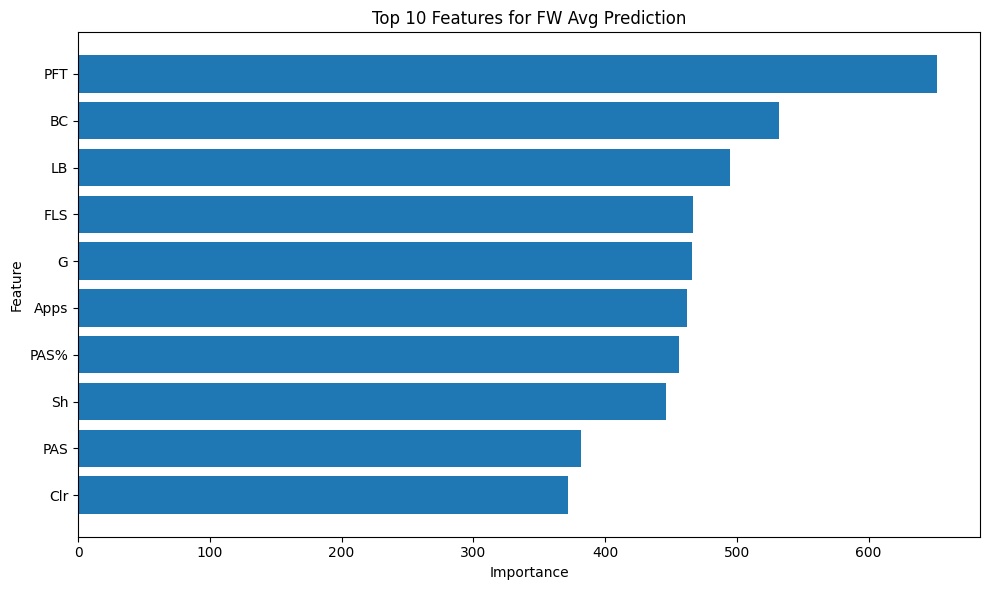


Top 10 features for MID:
feature  importance
   PAS%         806
     BC         677
      G         631
    Clr         528
    Int         512
     Sh         441
   Apps         434
    DIS         430
    DRA         424
     KP         387


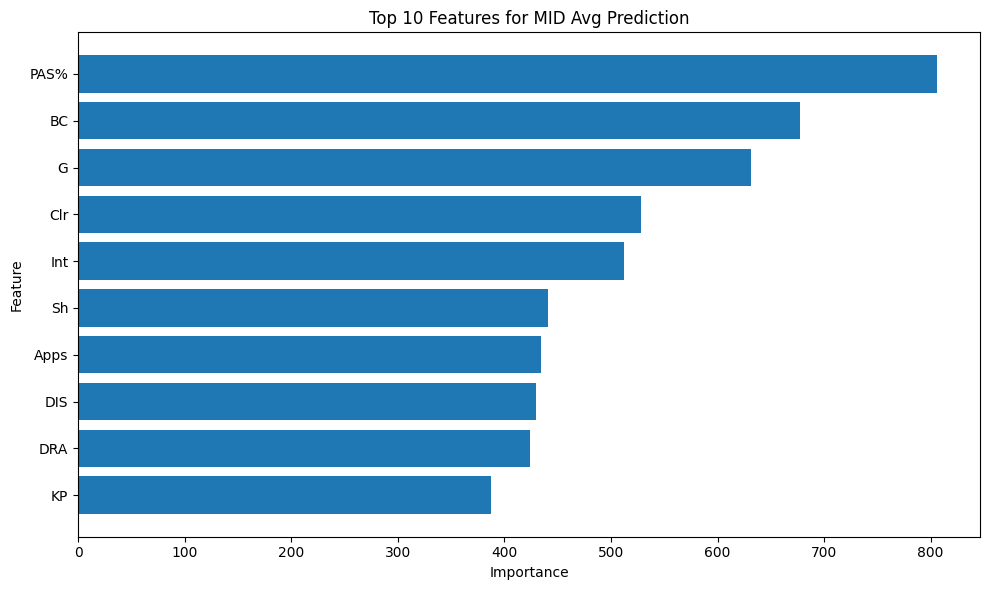


Top 10 features for DEF:
feature  importance
   Apps        1071
    Clr        1049
   PAS%         930
    DUW         846
     GC         673
      G         640
    REC         638
    PFT         626
    BLK         626
    PLS         610


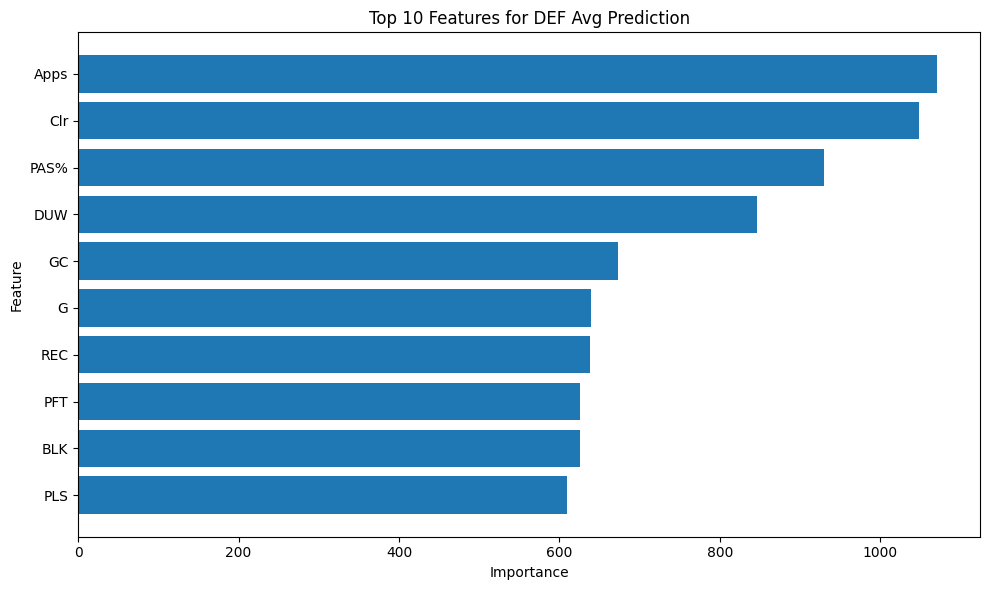


Top 10 features for GK:
feature  importance
     GC         300
   PAS%         270
     CS         227
    HCL         207
   APAS         197
    PUN         176
     KP         160
     Sv         148
    SIB         138
    REC         136


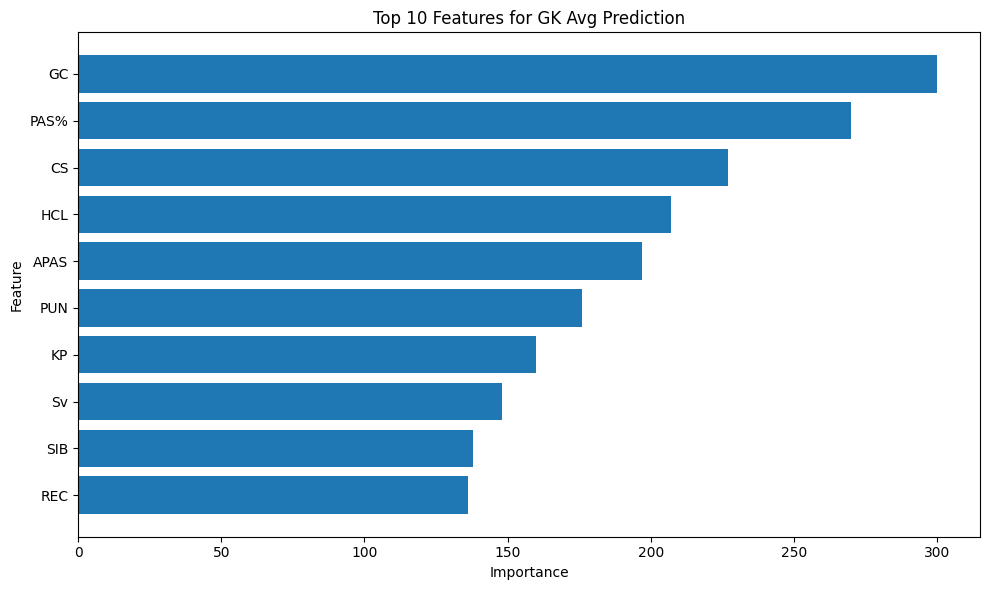

In [5]:
# Feature importance by position
for pos, model in models.items():
    feature_importance = pd.DataFrame({
        'feature': [
            'Apps', 'St', 'Min', 'G', 'PG', 'PMS', 'A', 'Sh', 'SoT', 'SOFF', 'WOOD', 'KP',
            'BC', 'BCM', 'PAS', 'APAS', 'PAS%', 'CRS', 'ACR', 'LB', 'LBW', 'TB', 'PFT',
            'Drb', 'DRA', 'DRP', 'Tkl', 'Int', 'Clr', 'BLK', 'LMT', 'REC', 'DUE', 'DUW',
            'AER', 'FDR', 'FLS', 'OFS', 'DIS', 'PLS', 'ERG', 'ELS', 'PCM', 'CS', 'GC',
            'Sv', 'SIB', 'SV%', 'PSV', 'HCL', 'PUN', 'YC', '2YC', 'RC', 'OG'
        ],
        'importance': model.named_steps['model'].feature_importances_
    }).sort_values('importance', ascending=False)

    print(f'\nTop 10 features for {pos}:')
    print(feature_importance.head(10).to_string(index=False))

    try:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(10, 6))
        top = feature_importance.head(10).copy()
        plt.barh(top['feature'][::-1], top['importance'][::-1])
        plt.title(f'Top 10 Features for {pos} Avg Prediction')
        plt.xlabel('Importance')
        plt.ylabel('Feature')
        plt.tight_layout()
        plt.show()
    except ImportError:
        pass